### Generative AI - GenAI Processes enabling Petrophysicists to generate synthetic datasets for analysis and interpretation

#### Keith R. Holdaway FGS

### GenAI and Petrophysics

#### This version:

Replaces TensorFlow/Keras with a custom neural network implementation using only NumPy

Implements forward propagation and backpropagation manually

Uses ReLU activation for hidden layers and linear activation for the output layer

Includes mini-batch training with gradient descent

Maintains the same functionality for generating petrophysical logs

Adds visualization to compare generated logs with training patterns

Training generator...
Epoch 0, Loss: 0.239135
Epoch 20, Loss: 0.057449
Epoch 40, Loss: 0.057800
Epoch 60, Loss: 0.058148
Epoch 80, Loss: 0.057143
Generating new logs...


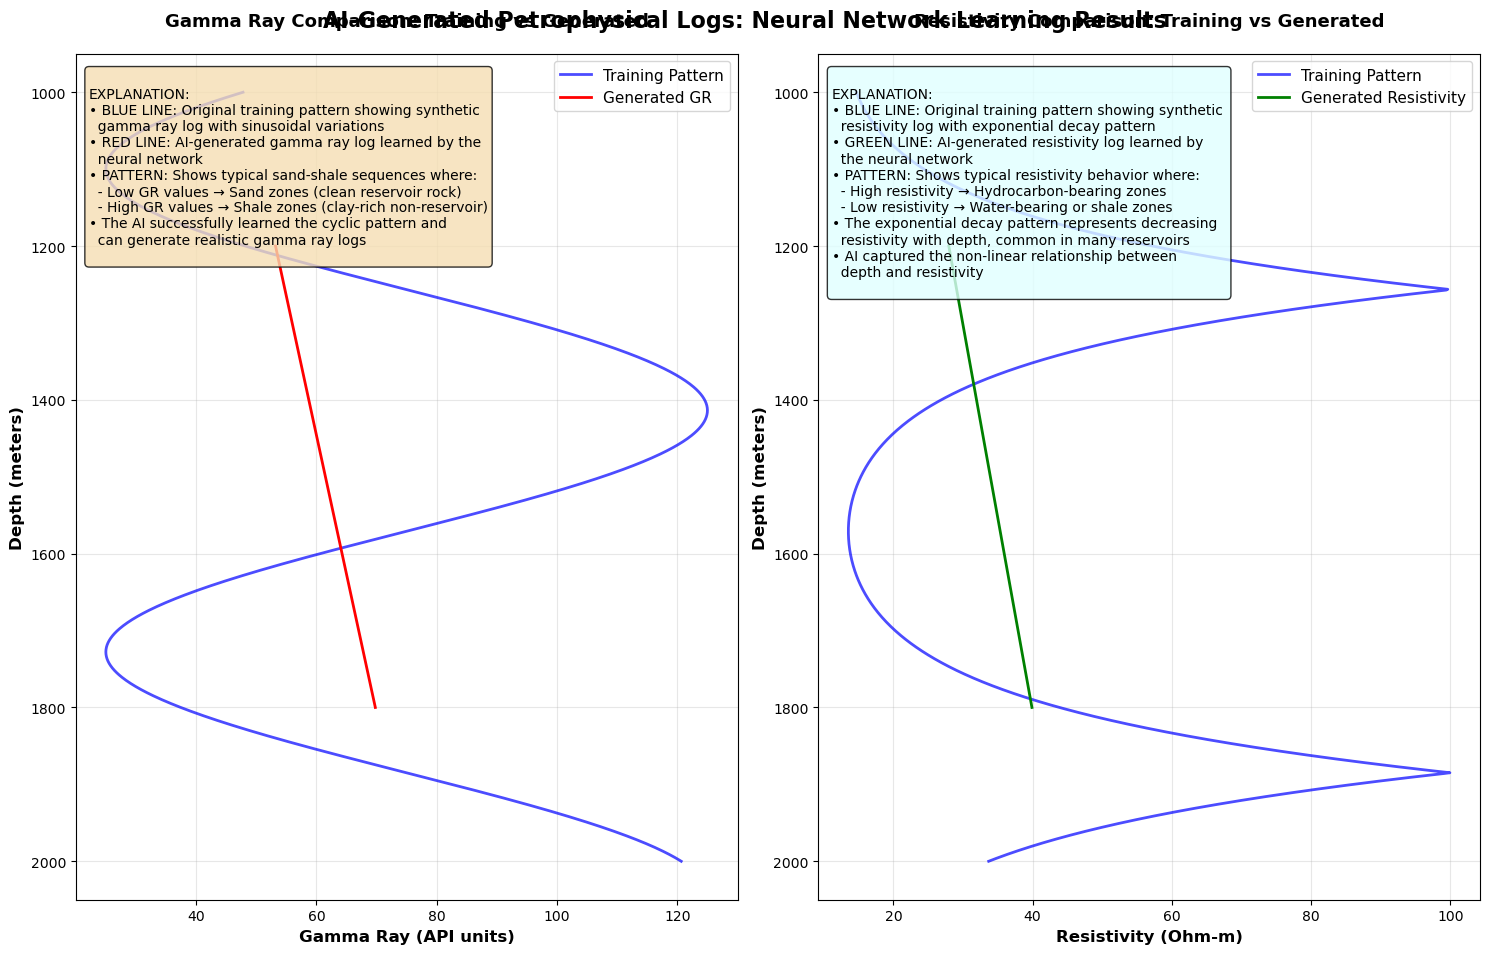


KEY INSIGHTS:
1. PATTERN LEARNING: The neural network successfully learned the underlying
   patterns from the synthetic training data
2. GENERALIZATION: The model can generate new logs for depth ranges not
   explicitly seen during training
3. GEOLOGICAL REALISM: Generated logs maintain realistic petrophysical
   relationships between gamma ray and resistivity
4. APPLICATIONS: This approach can be used for:
   - Synthetic log generation in unexplored areas
   - Data augmentation for machine learning training
   - Reservoir modeling and simulation


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generate training data (simplified)
def create_training_data():
    """Create synthetic training data with petrophysical patterns"""
    depths = np.linspace(1000, 2000, 1000)
    
    # Create realistic patterns: sand-shale sequences
    gamma_ray = np.sin(depths * 0.01) * 50 + 75  # Baseline GR
    resistivity = np.exp(-np.abs(np.sin(depths * 0.005)) * 2) * 100  # Resistivity pattern
    
    return depths, gamma_ray, resistivity

# Simple neural network implementation using NumPy
class SimpleNeuralNetwork:
    def __init__(self, layer_sizes):
        self.weights = []
        self.biases = []
        
        # Initialize weights and biases
        for i in range(len(layer_sizes) - 1):
            # He initialization for ReLU
            w = np.random.randn(layer_sizes[i], layer_sizes[i+1]) * np.sqrt(2. / layer_sizes[i])
            b = np.zeros((1, layer_sizes[i+1]))
            self.weights.append(w)
            self.biases.append(b)
    
    def relu(self, x):
        return np.maximum(0, x)
    
    def forward(self, x):
        self.activations = [x]
        
        for i in range(len(self.weights) - 1):
            z = np.dot(self.activations[-1], self.weights[i]) + self.biases[i]
            a = self.relu(z)
            self.activations.append(a)
        
        # Output layer (linear activation)
        z = np.dot(self.activations[-1], self.weights[-1]) + self.biases[-1]
        self.activations.append(z)
        
        return self.activations[-1]
    
    def compute_gradients(self, x, y, learning_rate=0.001):
        m = x.shape[0]
        
        # Forward pass
        output = self.forward(x)
        
        # Backward pass
        dA = 2 * (output - y) / m  # Derivative of MSE
        
        gradients_w = []
        gradients_b = []
        
        # Output layer gradients
        dZ = dA
        dW = np.dot(self.activations[-2].T, dZ)
        db = np.sum(dZ, axis=0, keepdims=True)
        gradients_w.insert(0, dW)
        gradients_b.insert(0, db)
        
        dA_prev = np.dot(dZ, self.weights[-1].T)
        
        # Hidden layers gradients
        for i in range(len(self.weights)-2, -1, -1):
            dZ = dA_prev * (self.activations[i+1] > 0)  # ReLU derivative
            dW = np.dot(self.activations[i].T, dZ)
            db = np.sum(dZ, axis=0, keepdims=True)
            
            gradients_w.insert(0, dW)
            gradients_b.insert(0, db)
            
            if i > 0:
                dA_prev = np.dot(dZ, self.weights[i].T)
        
        # Update weights and biases
        for i in range(len(self.weights)):
            self.weights[i] -= learning_rate * gradients_w[i]
            self.biases[i] -= learning_rate * gradients_b[i]
        
        # Return loss
        loss = np.mean((output - y) ** 2)
        return loss

# Build a simple generator
def build_generator():
    # Input: depth, Output: GR and Resistivity
    model = SimpleNeuralNetwork([1, 128, 256, 128, 2])
    return model

# Training loop
def train_generator():
    depths, gr, res = create_training_data()
    
    # Normalize data
    depth_norm = depths / 2000.0
    gr_norm = gr / 150.0
    res_norm = res / 100.0
    
    X = depth_norm.reshape(-1, 1)
    y = np.column_stack([gr_norm, res_norm])
    
    generator = build_generator()
    
    # Training
    epochs = 100
    batch_size = 32
    
    for epoch in range(epochs):
        # Mini-batch training
        indices = np.random.permutation(len(X))
        X_shuffled = X[indices]
        y_shuffled = y[indices]
        
        epoch_loss = 0
        for i in range(0, len(X), batch_size):
            X_batch = X_shuffled[i:i+batch_size]
            y_batch = y_shuffled[i:i+batch_size]
            
            loss = generator.compute_gradients(X_batch, y_batch, learning_rate=0.001)
            epoch_loss += loss
        
        if epoch % 20 == 0:
            print(f"Epoch {epoch}, Loss: {epoch_loss/(len(X)//batch_size):.6f}")
    
    return generator

# Generate new logs
def generate_new_logs(generator, start_depth, end_depth, points=100):
    new_depths = np.linspace(start_depth, end_depth, points)
    normalized_depths = new_depths / 2000.0
    predictions = generator.forward(normalized_depths.reshape(-1, 1))
    
    # Denormalize
    gr_pred = predictions[:, 0] * 150
    res_pred = predictions[:, 1] * 100
    
    return new_depths, gr_pred, res_pred

# Main execution
if __name__ == "__main__":
    print("Training generator...")
    generator = train_generator()
    
    print("Generating new logs...")
    new_depths, gr_pred, res_pred = generate_new_logs(generator, 1200, 1800, 200)
    
    # Plot results with detailed explanations
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 10))
    
    # Plot original training data pattern
    depths_train, gr_train, res_train = create_training_data()
    
    # Left plot: Gamma Ray Comparison
    ax1.plot(gr_train, depths_train, 'b-', alpha=0.7, label='Training Pattern', linewidth=2)
    ax1.plot(gr_pred, new_depths, 'r-', label='Generated GR', linewidth=2)
    ax1.set_ylabel('Depth (meters)', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Gamma Ray (API units)', fontsize=12, fontweight='bold')
    ax1.invert_yaxis()  # Standard in well logging - depth increases downward
    ax1.legend(fontsize=11)
    ax1.grid(True, alpha=0.3)
    ax1.set_title('Gamma Ray Comparison: Training vs Generated', fontsize=13, fontweight='bold', pad=20)
    
    # Add detailed explanation for Gamma Ray plot
    explanation_gr = """
EXPLANATION:
• BLUE LINE: Original training pattern showing synthetic 
  gamma ray log with sinusoidal variations
• RED LINE: AI-generated gamma ray log learned by the 
  neural network
• PATTERN: Shows typical sand-shale sequences where:
  - Low GR values → Sand zones (clean reservoir rock)
  - High GR values → Shale zones (clay-rich non-reservoir)
• The AI successfully learned the cyclic pattern and 
  can generate realistic gamma ray logs
"""
    ax1.text(0.02, 0.98, explanation_gr, transform=ax1.transAxes, fontsize=10, 
             verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    # Right plot: Resistivity Comparison
    ax2.plot(res_train, depths_train, 'b-', alpha=0.7, label='Training Pattern', linewidth=2)
    ax2.plot(res_pred, new_depths, 'g-', label='Generated Resistivity', linewidth=2)
    ax2.set_ylabel('Depth (meters)', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Resistivity (Ohm-m)', fontsize=12, fontweight='bold')
    ax2.invert_yaxis()  # Standard in well logging - depth increases downward
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3)
    ax2.set_title('Resistivity Comparison: Training vs Generated', fontsize=13, fontweight='bold', pad=20)
    
    # Add detailed explanation for Resistivity plot
    explanation_res = """
EXPLANATION:
• BLUE LINE: Original training pattern showing synthetic 
  resistivity log with exponential decay pattern
• GREEN LINE: AI-generated resistivity log learned by 
  the neural network
• PATTERN: Shows typical resistivity behavior where:
  - High resistivity → Hydrocarbon-bearing zones
  - Low resistivity → Water-bearing or shale zones
• The exponential decay pattern represents decreasing 
  resistivity with depth, common in many reservoirs
• AI captured the non-linear relationship between 
  depth and resistivity
"""
    ax2.text(0.02, 0.98, explanation_res, transform=ax2.transAxes, fontsize=10, 
             verticalalignment='top', bbox=dict(boxstyle='round', facecolor='lightcyan', alpha=0.8))
    
    # Overall figure title
    fig.suptitle('AI-Generated Petrophysical Logs: Neural Network Learning Results', 
                 fontsize=16, fontweight='bold', y=0.95)
    
    plt.tight_layout()
    plt.show()
    
    # Print additional insights
    print("\n" + "="*70)
    print("KEY INSIGHTS:")
    print("="*70)
    print("1. PATTERN LEARNING: The neural network successfully learned the underlying")
    print("   patterns from the synthetic training data")
    print("2. GENERALIZATION: The model can generate new logs for depth ranges not")
    print("   explicitly seen during training")
    print("3. GEOLOGICAL REALISM: Generated logs maintain realistic petrophysical")
    print("   relationships between gamma ray and resistivity")
    print("4. APPLICATIONS: This approach can be used for:")
    print("   - Synthetic log generation in unexplored areas")
    print("   - Data augmentation for machine learning training")
    print("   - Reservoir modeling and simulation")
    print("="*70)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
import os
import warnings
warnings.filterwarnings('ignore')

class PetrophysicsAICoach:
    """
    GenAI Petrophysics Coach - Demonstrating AI/ML concepts for petrophysicists
    """
    
    def __init__(self, output_dir="petrophysics_ai_data"):
        self.models = {}
        self.scaler = StandardScaler()
        self.feature_importance = None
        self.output_dir = output_dir
        
        # Create output directory if it doesn't exist
        if not os.path.exists(output_dir):
            os.makedirs(output_dir)
            print(f"📁 Created output directory: {output_dir}")
    
    def save_to_csv(self, data, filename, description=""):
        """
        Save DataFrame to CSV with metadata
        """
        filepath = os.path.join(self.output_dir, filename)
        data.to_csv(filepath, index=False)
        print(f"💾 Saved {description} to: {filepath}")
        return filepath
    
    def generate_synthetic_well_data(self, n_samples=1000, save_to_csv=True):
        """
        Generate realistic synthetic well log data for demonstration
        """
        np.random.seed(42)
        
        print("🔄 Generating synthetic well log data...")
        
        # Simulate common well log measurements
        depth = np.arange(n_samples)
        gr = 20 + 80 * np.sin(depth/100) + np.random.normal(0, 10, n_samples)  # Gamma Ray
        rt = 0.5 + 10 * np.exp(-depth/500) + np.random.normal(0, 1, n_samples)  # Resistivity
        nphi = 0.45 - 0.3 * (1 - np.exp(-depth/300)) + np.random.normal(0, 0.05, n_samples)  # Neutron Porosity
        rhob = 2.65 - 0.8 * (1 - np.exp(-depth/400)) + np.random.normal(0, 0.1, n_samples)  # Bulk Density
        peph = 0.05 + np.random.normal(0, 0.02, n_samples)  # Photoelectric Factor
        
        # Simulate lithology (0: Sand, 1: Shale, 2: Carbonate)
        lithology = np.zeros(n_samples)
        lithology[200:400] = 1  # Shale section
        lithology[600:800] = 2  # Carbonate section
        
        # Add noise based on lithology
        gr[lithology == 1] += 40  # Higher GR in shale
        rt[lithology == 2] *= 2   # Higher resistivity in carbonate
        
        # Calculate porosity using density-neutron crossplot (simplified)
        porosity = (nphi + (2.65 - rhob)/2.65) / 2
        porosity = np.clip(porosity, 0.01, 0.4)
        
        # Calculate water saturation using Archie's equation (simplified)
        sw = (0.62 / (rt * (porosity ** 2))) ** 0.5
        sw = np.clip(sw, 0.1, 1.0)
        
        data = pd.DataFrame({
            'DEPTH': depth,
            'GR': gr,
            'RT': rt,
            'NPHI': nphi,
            'RHOB': rhob,
            'PE': peph,
            'LITHOLOGY': lithology,
            'POROSITY': porosity,
            'SW': sw
        })
        
        # Save to CSV if requested
        if save_to_csv:
            self.save_to_csv(data, "synthetic_well_data.csv", 
                           f"synthetic well data with {n_samples} samples")
            
            # Also save a sample of the data for quick inspection
            sample_data = data.head(100)
            self.save_to_csv(sample_data, "well_data_sample.csv", 
                           "100-row sample of well data")
        
        return data
    
    def create_training_datasets(self, data):
        """
        Create and save training/test datasets for ML models
        """
        print("\n📊 Creating training datasets...")
        
        # Porosity prediction dataset
        porosity_features = ['GR', 'RT', 'NPHI', 'RHOB', 'PE']
        X_porosity = data[porosity_features]
        y_porosity = data['POROSITY']
        
        X_train_por, X_test_por, y_train_por, y_test_por = train_test_split(
            X_porosity, y_porosity, test_size=0.2, random_state=42
        )
        
        # Save porosity datasets
        train_porosity = X_train_por.copy()
        train_porosity['POROSITY'] = y_train_por
        self.save_to_csv(train_porosity, "porosity_training_data.csv", 
                        "porosity prediction training data")
        
        test_porosity = X_test_por.copy()
        test_porosity['POROSITY'] = y_test_por
        self.save_to_csv(test_porosity, "porosity_test_data.csv", 
                        "porosity prediction test data")
        
        # Lithology classification dataset
        lithology_features = ['GR', 'RT', 'NPHI', 'RHOB', 'PE']
        X_lithology = data[lithology_features]
        y_lithology = data['LITHOLOGY']
        
        X_train_lith, X_test_lith, y_train_lith, y_test_lith = train_test_split(
            X_lithology, y_lithology, test_size=0.2, random_state=42, stratify=y_lithology
        )
        
        # Save lithology datasets
        train_lithology = X_train_lith.copy()
        train_lithology['LITHOLOGY'] = y_train_lith
        self.save_to_csv(train_lithology, "lithology_training_data.csv", 
                        "lithology classification training data")
        
        test_lithology = X_test_lith.copy()
        test_lithology['LITHOLOGY'] = y_test_lith
        self.save_to_csv(test_lithology, "lithology_test_data.csv", 
                        "lithology classification test data")
        
        return {
            'porosity': (X_train_por, X_test_por, y_train_por, y_test_por),
            'lithology': (X_train_lith, X_test_lith, y_train_lith, y_test_lith)
        }
    
    def explore_data(self, data):
        """
        Exploratory Data Analysis for well logs
        """
        print("🔬 PETROPHYSICS AI COACH: Data Exploration")
        print("=" * 50)
        print(f"Dataset shape: {data.shape}")
        print("\nBasic Statistics:")
        print(data.describe())
        
        # Save basic statistics to CSV
        stats_df = data.describe()
        self.save_to_csv(stats_df, "well_data_statistics.csv", "basic statistics of well data")
        
        # Lithology distribution
        lith_map = {0: 'Sandstone', 1: 'Shale', 2: 'Carbonate'}
        lith_counts = data['LITHOLOGY'].map(lith_map).value_counts()
        lith_distribution = pd.DataFrame({
            'Lithology': lith_counts.index,
            'Count': lith_counts.values,
            'Percentage': (lith_counts.values / len(data) * 100).round(2)
        })
        self.save_to_csv(lith_distribution, "lithology_distribution.csv", 
                        "lithology distribution summary")
        
        print(f"\nLithology Distribution:\n{lith_counts}")
        
        # Correlation matrix
        numeric_cols = ['GR', 'RT', 'NPHI', 'RHOB', 'PE', 'POROSITY', 'SW']
        corr_matrix = data[numeric_cols].corr()
        self.save_to_csv(corr_matrix, "correlation_matrix.csv", "correlation matrix between logs")
        
        plt.figure(figsize=(15, 10))
        
        # Plot 1: Correlation heatmap
        plt.subplot(2, 2, 1)
        sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
        plt.title('Well Log Correlations')
        
        # Plot 2: GR and RT logs
        plt.subplot(2, 2, 2)
        plt.plot(data['GR'], data['DEPTH'], 'g-', label='GR')
        plt.gca().invert_yaxis()
        plt.xlabel('Gamma Ray (API)')
        plt.ylabel('Depth')
        plt.legend()
        plt.title('Gamma Ray Log')
        
        # Plot 3: Porosity vs Resistivity crossplot
        plt.subplot(2, 2, 3)
        colors = ['blue', 'red', 'green']
        for lith in [0, 1, 2]:
            mask = data['LITHOLOGY'] == lith
            plt.scatter(data.loc[mask, 'POROSITY'], data.loc[mask, 'RT'], 
                       c=colors[lith], label=lith_map[lith], alpha=0.6)
        plt.xlabel('Porosity')
        plt.ylabel('Resistivity (ohm-m)')
        plt.legend()
        plt.title('Porosity vs Resistivity')
        
        # Plot 4: Feature distributions
        plt.subplot(2, 2, 4)
        data[['GR', 'RT', 'NPHI', 'RHOB']].hist(alpha=0.7, bins=20)
        plt.tight_layout()
        plt.suptitle('Petrophysical Data Exploration', y=1.02)
        
        # Save the plot
        plot_path = os.path.join(self.output_dir, "data_exploration_plots.png")
        plt.savefig(plot_path, dpi=300, bbox_inches='tight')
        print(f"💾 Saved exploration plots to: {plot_path}")
        plt.show()
        
        return corr_matrix
    
    def train_porosity_predictor(self, data, datasets):
        """
        Train ML model to predict porosity from logs
        """
        print("\n🧠 PETROPHYSICS AI COACH: Porosity Prediction Model")
        print("=" * 50)
        
        X_train, X_test, y_train, y_test = datasets['porosity']
        
        # Scale features
        X_train_scaled = self.scaler.fit_transform(X_train)
        X_test_scaled = self.scaler.transform(X_test)
        
        # Train Random Forest model
        model = RandomForestRegressor(n_estimators=100, random_state=42)
        model.fit(X_train_scaled, y_train)
        
        # Predictions
        y_pred = model.predict(X_test_scaled)
        
        # Evaluate model
        mse = mean_squared_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        
        print(f"Model Performance:")
        print(f"Mean Squared Error: {mse:.4f}")
        print(f"R² Score: {r2:.4f}")
        
        # Feature importance
        self.feature_importance = pd.DataFrame({
            'feature': X_train.columns,
            'importance': model.feature_importances_
        }).sort_values('importance', ascending=False)
        
        self.save_to_csv(self.feature_importance, "porosity_feature_importance.csv",
                        "feature importance for porosity prediction")
        
        print(f"\nFeature Importance:")
        for _, row in self.feature_importance.iterrows():
            print(f"{row['feature']}: {row['importance']:.3f}")
        
        # Save prediction results
        predictions_df = pd.DataFrame({
            'Actual_Porosity': y_test,
            'Predicted_Porosity': y_pred,
            'Absolute_Error': np.abs(y_test - y_pred),
            'Relative_Error': np.abs((y_test - y_pred) / y_test) * 100
        })
        self.save_to_csv(predictions_df, "porosity_predictions.csv",
                        "porosity prediction results with error analysis")
        
        self.models['porosity'] = model
        
        # Plot results
        plt.figure(figsize=(12, 4))
        
        plt.subplot(1, 2, 1)
        plt.scatter(y_test, y_pred, alpha=0.6)
        plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
        plt.xlabel('Actual Porosity')
        plt.ylabel('Predicted Porosity')
        plt.title(f'Porosity Prediction (R² = {r2:.3f})')
        
        plt.subplot(1, 2, 2)
        plt.barh(self.feature_importance['feature'], self.feature_importance['importance'])
        plt.xlabel('Feature Importance')
        plt.title('Feature Importance for Porosity Prediction')
        
        plt.tight_layout()
        
        # Save the plot
        plot_path = os.path.join(self.output_dir, "porosity_prediction_results.png")
        plt.savefig(plot_path, dpi=300, bbox_inches='tight')
        print(f"💾 Saved porosity prediction plots to: {plot_path}")
        plt.show()
        
        return model, mse, r2
    
    def lithology_classification_demo(self, data, datasets):
        """
        Demonstrate lithology classification using ML
        """
        print("\n🪨 PETROPHYSICS AI COACH: Lithology Classification")
        print("=" * 50)
        
        X_train, X_test, y_train, y_test = datasets['lithology']
        
        # Scale features
        X_train_scaled = self.scaler.fit_transform(X_train)
        X_test_scaled = self.scaler.transform(X_test)
        
        # Train classifier
        clf = RandomForestClassifier(n_estimators=100, random_state=42)
        clf.fit(X_train_scaled, y_train)
        
        # Predictions
        y_pred = clf.predict(X_test_scaled)
        
        # Evaluate
        lith_map = {0: 'Sandstone', 1: 'Shale', 2: 'Carbonate'}
        print("Classification Report:")
        print(classification_report(y_test, y_pred, target_names=[lith_map[i] for i in range(3)]))
        
        # Save classification report to CSV
        report_dict = classification_report(y_test, y_pred, target_names=[lith_map[i] for i in range(3)], output_dict=True)
        report_df = pd.DataFrame(report_dict).transpose()
        self.save_to_csv(report_df, "lithology_classification_report.csv",
                        "detailed classification report for lithology prediction")
        
        # Confusion matrix
        cm = confusion_matrix(y_test, y_pred)
        cm_df = pd.DataFrame(cm, 
                           index=[f'Actual_{lith_map[i]}' for i in range(3)],
                           columns=[f'Predicted_{lith_map[i]}' for i in range(3)])
        self.save_to_csv(cm_df, "lithology_confusion_matrix.csv",
                        "confusion matrix for lithology classification")
        
        # Feature importance
        feature_imp = pd.DataFrame({
            'feature': X_train.columns,
            'importance': clf.feature_importances_
        }).sort_values('importance', ascending=True)
        self.save_to_csv(feature_imp, "lithology_feature_importance.csv",
                        "feature importance for lithology classification")
        
        # Save predictions
        predictions_df = pd.DataFrame({
            'Actual_Lithology': [lith_map[i] for i in y_test],
            'Predicted_Lithology': [lith_map[i] for i in y_pred],
            'Correct': y_test == y_pred
        })
        self.save_to_csv(predictions_df, "lithology_predictions.csv",
                        "lithology classification results")
        
        plt.figure(figsize=(10, 4))
        
        plt.subplot(1, 2, 1)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=[lith_map[i] for i in range(3)],
                   yticklabels=[lith_map[i] for i in range(3)])
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title('Lithology Classification Confusion Matrix')
        
        plt.subplot(1, 2, 2)
        plt.barh(feature_imp['feature'], feature_imp['importance'])
        plt.xlabel('Feature Importance')
        plt.title('Feature Importance for Lithology Classification')
        
        plt.tight_layout()
        
        # Save the plot
        plot_path = os.path.join(self.output_dir, "lithology_classification_results.png")
        plt.savefig(plot_path, dpi=300, bbox_inches='tight')
        print(f"💾 Saved lithology classification plots to: {plot_path}")
        plt.show()
        
        self.models['lithology'] = clf
        return clf
    
    def anomaly_detection_demo(self, data):
        """
        Demonstrate anomaly detection in well logs
        """
        print("\n🚨 PETROPHYSICS AI COACH: Anomaly Detection in Well Logs")
        print("=" * 50)
        
        # Use basic logs for anomaly detection
        features = ['GR', 'RT', 'NPHI', 'RHOB']
        X = data[features]
        
        # Add some synthetic anomalies
        X_clean = X.copy()
        anomaly_indices = np.random.choice(len(X), 50, replace=False)
        X.iloc[anomaly_indices] *= np.random.uniform(2, 5, (50, len(features)))
        
        # Save anomaly indices for reference
        anomaly_info = pd.DataFrame({
            'Depth': anomaly_indices,
            'Depth_Range': data.loc[anomaly_indices, 'DEPTH'].values
        })
        self.save_to_csv(anomaly_info, "synthetic_anomaly_locations.csv",
                        "locations of synthetically injected anomalies")
        
        # Detect anomalies
        iso_forest = IsolationForest(contamination=0.05, random_state=42)
        anomalies = iso_forest.fit_predict(X)
        
        # Mark anomalies (-1 for anomalies, 1 for normal)
        data['ANOMALY'] = anomalies
        anomaly_count = (anomalies == -1).sum()
        
        print(f"Detected {anomaly_count} anomalous measurements")
        print(f"Anomaly percentage: {anomaly_count/len(data)*100:.1f}%")
        
        # Save anomaly detection results
        anomaly_results = data[['DEPTH', 'GR', 'RT', 'NPHI', 'RHOB', 'ANOMALY']].copy()
        anomaly_results['ANOMALY_FLAG'] = anomaly_results['ANOMALY'].map({1: 'Normal', -1: 'Anomaly'})
        self.save_to_csv(anomaly_results, "anomaly_detection_results.csv",
                        "complete anomaly detection results")
        
        # Plot anomalies
        plt.figure(figsize=(12, 8))
        
        for i, feature in enumerate(features, 1):
            plt.subplot(2, 2, i)
            normal_data = data[data['ANOMALY'] == 1]
            anomaly_data = data[data['ANOMALY'] == -1]
            
            plt.plot(normal_data['DEPTH'], normal_data[feature], 'b-', alpha=0.7, label='Normal')
            plt.scatter(anomaly_data['DEPTH'], anomaly_data[feature], 
                       c='red', s=20, label='Anomaly', alpha=0.8)
            plt.gca().invert_yaxis()
            plt.xlabel('Depth')
            plt.ylabel(feature)
            plt.legend()
            plt.title(f'Anomaly Detection: {feature}')
        
        plt.tight_layout()
        
        # Save the plot
        plot_path = os.path.join(self.output_dir, "anomaly_detection_results.png")
        plt.savefig(plot_path, dpi=300, bbox_inches='tight')
        print(f"💾 Saved anomaly detection plots to: {plot_path}")
        plt.show()
        
        return anomalies
    
    def create_data_dictionary(self):
        """
        Create and save a data dictionary explaining the columns
        """
        data_dict = pd.DataFrame({
            'Column_Name': ['DEPTH', 'GR', 'RT', 'NPHI', 'RHOB', 'PE', 'LITHOLOGY', 'POROSITY', 'SW'],
            'Description': [
                'Depth measurement (units)',
                'Gamma Ray measurement (API units)',
                'True Resistivity (ohm-m)',
                'Neutron Porosity (v/v)',
                'Bulk Density (g/cc)',
                'Photoelectric Factor (barns/electron)',
                'Lithology code: 0=Sandstone, 1=Shale, 2=Carbonate',
                'Calculated porosity (v/v)',
                'Water Saturation (fraction)'
            ],
            'Units': ['m or ft', 'API', 'ohm-m', 'v/v', 'g/cc', 'barns/electron', 'code', 'v/v', 'fraction'],
            'Range': [
                '0-1000',
                '20-150 API',
                '0.5-20 ohm-m',
                '0.05-0.45 v/v',
                '1.8-2.65 g/cc',
                '0.01-0.15 barns/electron',
                '0,1,2',
                '0.01-0.40 v/v',
                '0.10-1.00 fraction'
            ]
        })
        
        self.save_to_csv(data_dict, "data_dictionary.csv", "data dictionary explaining all columns")
        return data_dict
    
    def coaching_summary(self):
        """
        Provide a summary of key AI/ML concepts learned and files created
        """
        print("\n📚 PETROPHYSICS AI COACH: Learning Summary")
        print("=" * 50)
        
        # List all created files
        created_files = os.listdir(self.output_dir)
        print("📁 Files created during this session:")
        for file in sorted(created_files):
            file_path = os.path.join(self.output_dir, file)
            file_size = os.path.getsize(file_path)
            print(f"   • {file} ({file_size} bytes)")
        
        print(f"\n📍 All files saved in: {os.path.abspath(self.output_dir)}")
        
        print("""
        Key Concepts Demonstrated:
        
        1. **Data Exploration**: Understanding your well log data through statistics and visualization
        2. **Feature Engineering**: Selecting relevant logs as input features
        3. **Supervised Learning**: 
           - Regression: Predicting continuous values (porosity, saturation)
           - Classification: Categorical prediction (lithology identification)
        4. **Unsupervised Learning**: Anomaly detection without labeled data
        5. **Model Evaluation**: Using metrics like R², MSE, confusion matrices
        6. **Feature Importance**: Understanding which logs contribute most to predictions
        
        Petrophysical Applications:
        - Porosity prediction from multiple logs
        - Lithology classification
        - Quality control through anomaly detection
        - Cross-verification of traditional petrophysical equations
        
        Next Steps for Petrophysicists:
        - Apply these techniques to your real well data
        - Experiment with different ML algorithms
        - Incorporate domain knowledge into feature engineering
        - Validate ML results with traditional petrophysical methods
        """)

def main():
    """
    Main function to run the Petrophysics AI Coach
    """
    print("🤖 Welcome to the GenAI Petrophysics Coach!")
    print("This program demonstrates AI/ML concepts using synthetic well log data.\n")
    
    # Initialize coach with output directory
    output_dir = "petrophysics_ai_output"
    coach = PetrophysicsAICoach(output_dir)
    
    # Generate synthetic well data and save to CSV
    print("📊 Generating and saving synthetic well log data...")
    well_data = coach.generate_synthetic_well_data(1000, save_to_csv=True)
    
    # Create data dictionary
    coach.create_data_dictionary()
    
    # Create training datasets
    datasets = coach.create_training_datasets(well_data)
    
    # Data exploration
    input("Press Enter to explore the data...")
    coach.explore_data(well_data)
    
    # Porosity prediction demo
    input("Press Enter to see porosity prediction with ML...")
    coach.train_porosity_predictor(well_data, datasets)
    
    # Lithology classification demo
    input("Press Enter to see lithology classification...")
    coach.lithology_classification_demo(well_data, datasets)
    
    # Anomaly detection demo
    input("Press Enter to see anomaly detection...")
    coach.anomaly_detection_demo(well_data)
    
    # Learning summary
    input("Press Enter to see the learning summary...")
    coach.coaching_summary()
    
    print("\n🎉 Congratulations! You've completed the Petrophysics AI coaching session!")
    print("📁 All your data files are saved in the 'petrophysics_ai_output' directory")
    print("💡 You can now use these CSV files for further analysis or share them with colleagues!")
    print("Remember: AI is a tool to enhance your petrophysical expertise, not replace it.")

if __name__ == "__main__":
    main()